# Titanic Survival Analysis

## Introduction

The Titanic dataset contains information about passengers who travelled on the Titanic ship.

This project aims to analyze passenger survival patterns based on gender, passenger class, and age.

## Objectives
1. Load the Titanic dataset.
2. Clean the dataset.
3. Analyze passenger survival patterns.
4. Create visualizations using Seaborn and Matplotlib.
5. Draw conclusions from the analysis.

## 1. Import Required Libraries

We use the following Python libraries:

- Pandas: For data manipulation and analysis.
- Matplotlib: For creating graphs.
- Seaborn: For statistical data visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Titanic Dataset

We load the train.csv file downloaded from Kaggle.

This dataset contains passenger information, including their survival status.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [4]:
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Dataset Inspection

We inspect the dataset to understand:

- Number of rows and columns.
- Column names and data types.
- Missing values.
- Duplicate records.

In [5]:
print("Dataset Shape:", df.shape)

df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin       

## 4. Data Cleaning

Data cleaning is performed to improve data quality.

Steps:
1. Fill missing Age values using median.
2. Fill missing Embarked values using mode.
3. Fill missing Fare values using median.
4. Remove the Cabin column because it contains many missing values.
5. Remove duplicate records.

In [6]:
df = df.drop_duplicates()

df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

df["Fare"] = df["Fare"].fillna(df["Fare"].median())

df = df.drop("Cabin", axis=1)

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [7]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


## 5. Survival Analysis by Gender

In this section, we compare the survival rates of male and female passengers.

We use groupby() to calculate the average survival rate for each gender.

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


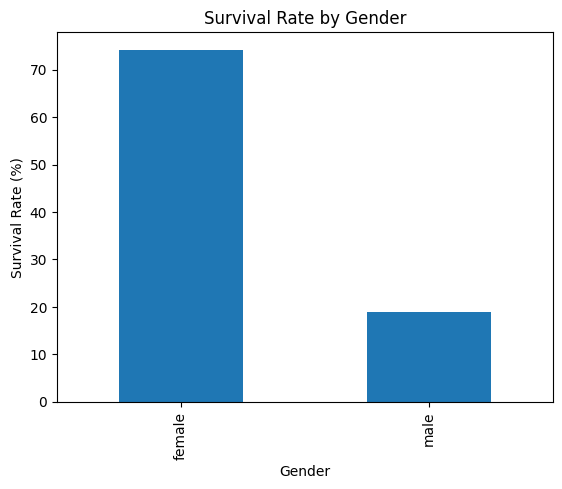

In [8]:
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print(gender_survival)

gender_survival.plot(kind="bar")
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.show()

### Insight: Survival Rate by Gender

The bar chart shows the survival rate of male and female passengers.

- Female passengers had a survival rate of approximately 74%.
- Male passengers had a survival rate of approximately 19%.

Conclusion: Female passengers had a significantly higher survival rate than male passengers.

## 6. Survival Analysis by Passenger Class

We analyze whether passenger class affected survival chances.

The dataset contains three classes:
- 1: First Class
- 2: Second Class
- 3: Third Class

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


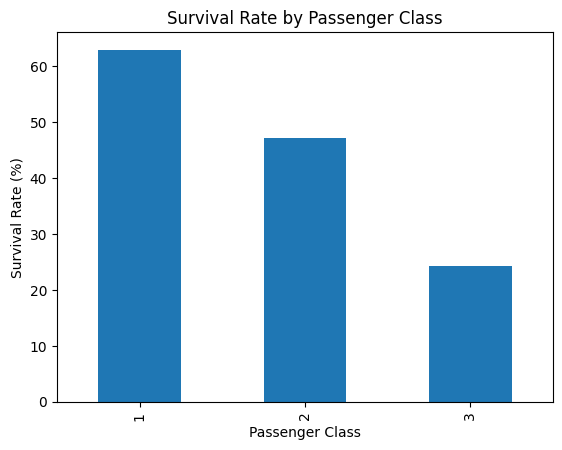

In [9]:
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print(class_survival)

class_survival.plot(kind="bar")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.show()

### Insight: Survival Rate by Passenger Class

The bar chart shows the survival rate of passengers in different classes.

- First-class passengers had a survival rate of approximately 63%.
- Second-class passengers had a survival rate of approximately 47%.
- Third-class passengers had a survival rate of approximately 24%.

Conclusion: First-class passengers had the highest survival rate, while third-class passengers had the lowest survival rate.

## 7. Survival Rate by Age Group

We divide passengers into different age groups:

- Child: 0–12
- Teen: 13–18
- Adult: 19–35
- Middle-aged: 36–60
- Senior: 61+

We calculate the survival rate for each age group.

AgeGroup
Child          57.971014
Teen           42.857143
Adult          35.327103
Middle-aged    40.000000
Senior         22.727273
Name: Survived, dtype: float64


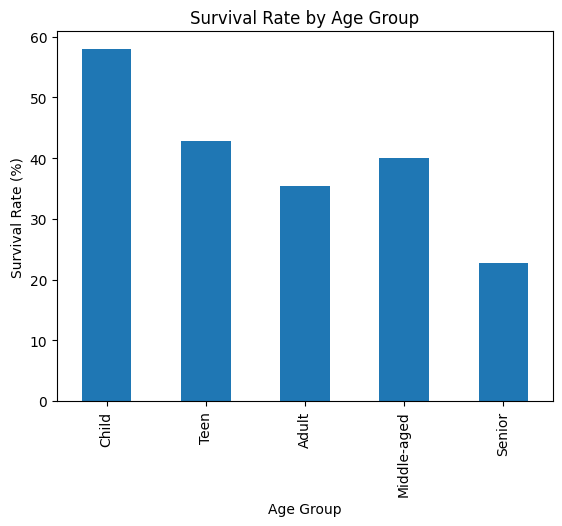

In [10]:
bins = [0, 12, 18, 35, 60, 100]

labels = ["Child", "Teen", "Adult", "Middle-aged", "Senior"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_survival = df.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print(age_survival)

age_survival.plot(kind="bar")
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.show()

### Titanic Survival Rate by Age Group

* **Children Survived Most (~58%):** Highest survival rate across all groups, reflecting the *"women and children first"* evacuation protocol.
* **Seniors Survived Least (~23%):** Lowest survival rate, likely due to mobility barriers during the emergency.
* **Middle-Aged Spike (~40%):** Outperformed general **Adults (~35%)**, largely because older passengers were more heavily concentrated in **First Class** with better lifeboat access.
* **Teens Ranked Second (~43%):** Benefited from both youth priority and physical agility.


## 8. Age Distribution of Passengers

We use a histogram to understand the distribution of passenger ages.

The histogram helps identify which age ranges had more passengers.

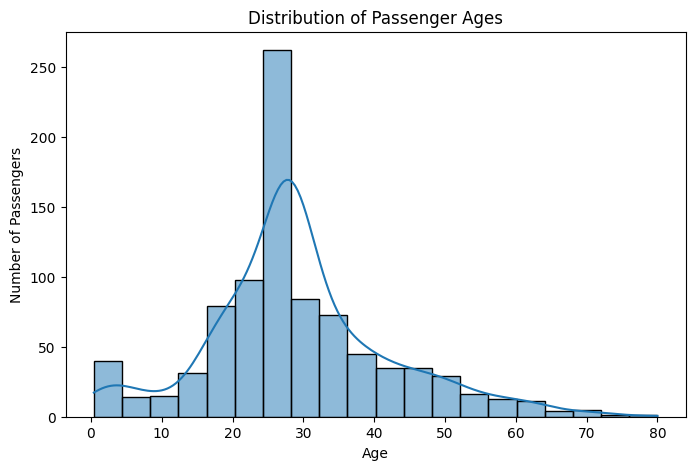

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

## 9. Conclusion

From the Titanic survival analysis, we studied:

1. Survival rates of male and female passengers.
2. The impact of passenger class on survival.
3. Survival rates across different age groups.
4. Distribution of passenger ages.

The graphs help us understand the survival patterns among Titanic passengers.